# Task 3: Exploratory Data Analysis

We explore `cleaned_data.csv` (80 study/work sessions) for our four questions: noise, task type, location, and sleep vs. focus.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [4]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Visual Analytics/cleaned_data.csv",keep_default_na=False, na_values=[""])
df.shape

(80, 33)

In [5]:
df.head()

,Timestamp,Date,Start_Time,End_Time,Task_Type,Task_Interest,Task_Difficulty,Planned_Duration,Time_to_First_Distraction,Num_Distractions,...,Time_to_First_Distraction_imputed,Total_Duration_Minutes,Duration_Flag_Long,strategy_phone_in_another_room,strategy_focus_app,strategy_background_music,strategy_noise_cancelling_headphones,strategy_timer,strategy_none,strategy_other
0,9/21/26 12:24,2026-09-21,08:30:00,11:00:00,Studying,5,7,120.0,10.0,16,...,False,150,False,0,0,0,1,0,0,0
1,9/21/26 12:41,2026-09-21,10:00:00,11:25:00,Writing,5,7,90.0,3.0,19,...,False,85,False,0,0,1,1,0,0,0
2,9/21/26 13:06,2026-09-21,11:15:00,12:40:00,Reading,4,8,90.0,3.0,21,...,False,85,False,0,0,0,0,0,1,0
3,9/21/26 23:14,2026-09-21,20:00:00,20:25:00,Homework/Assignments,6,4,30.0,4.0,5,...,False,25,False,0,0,0,0,0,1,0
4,9/22/26 01:02,2026-09-22,21:00:00,09:25:00,Studying,7,5,60.0,13.0,1,...,False,745,True,0,0,0,0,1,0,0


In [6]:
df.isna().sum()

,0
Timestamp,0
Date,0
Start_Time,0
End_Time,0
Task_Type,0
Task_Interest,0
Task_Difficulty,0
Planned_Duration,0
Time_to_First_Distraction,0
Num_Distractions,0


## Quick look at the data

In [7]:
df["Task_Type"].value_counts()

,count
Task_Type,
Studying,34
Homework/Assignments,14
Writing,10
Reading,10
Meeting,9
Other,3


In [8]:
df["Location"].value_counts()

,count
Location,
Home,34
Other,22
Library,17
Cafe,7


In [9]:
df["Noise_Level"].value_counts()

,count
Noise_Level,
Quiet,36
Moderate,21
Very Quiet,20
Noisy,3


## Fig 1. Distractions by noise level

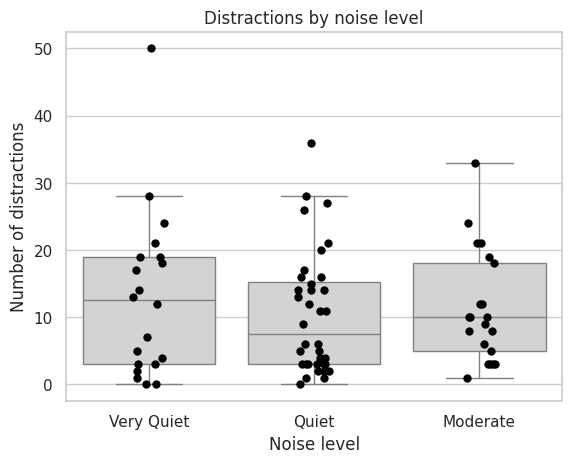

In [10]:
noise_order = ["Very Quiet", "Quiet", "Moderate"]

sns.boxplot(data=df, x="Noise_Level", y="Num_Distractions", order=noise_order, color="lightgray", showfliers=False)
sns.stripplot(data=df, x="Noise_Level", y="Num_Distractions", order=noise_order, color="black", size=6)
plt.title("Distractions by noise level")
plt.xlabel("Noise level")
plt.ylabel("Number of distractions")
plt.show()

In [11]:
# Compare mean vs median for each noise level
df.groupby("Noise_Level")["Num_Distractions"].agg(["count", "mean", "median"]).round(1)

,count,mean,median
Noise_Level,,,
Moderate,21,11.4,10.0
Noisy,3,13.7,13.0
Quiet,36,10.4,7.5
Very Quiet,20,13.0,12.5


Quieter didn’t mean fewer distractions. “Quiet” sessions had the lowest median (7.5), while “Very Quiet” sessions were higher (12.5). Noise alone doesn’t explain distractions.

## Fig 2. Focus by location

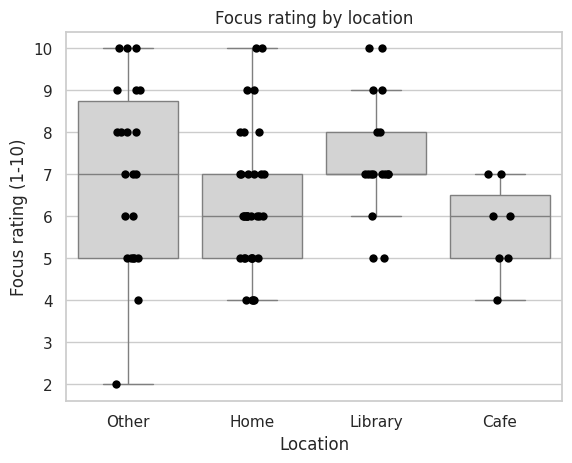

In [12]:
sns.boxplot(data=df, x="Location", y="Focus_Rating", color="lightgray", showfliers=False)
sns.stripplot(data=df, x="Location", y="Focus_Rating", color="black", size=6)
plt.title("Focus rating by location")
plt.ylabel("Focus rating (1-10)")
plt.show()

In [13]:
# How many sessions of each noise level happened at each location?
pd.crosstab(df["Location"], df["Noise_Level"])

Noise_Level,Moderate,Noisy,Quiet,Very Quiet
Location,,,,
Cafe,5,2,0,0
Home,11,0,14,9
Library,1,0,7,9
Other,4,1,15,2


The library had the highest focus (mean 7.4) and the café had the lowest (5.7). The crosstab shows location and noise overlap: every café session was Moderate or Noisy, and nearly all library sessions were Quiet or Very Quiet.

## Fig 3. Sleep vs. focus

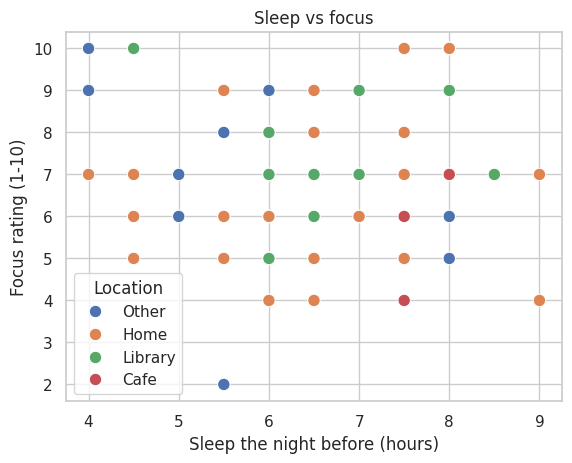

Correlation: 0.04


In [14]:
sns.scatterplot(data=df, x="Sleep_Hours", y="Focus_Rating", hue="Location", s=80)
plt.title("Sleep vs focus")
plt.xlabel("Sleep the night before (hours)")
plt.ylabel("Focus rating (1-10)")
plt.show()

print("Correlation:", round(df["Sleep_Hours"].corr(df["Focus_Rating"], method="spearman"), 2))

We expected more sleep to mean better focus, but there is no clear pattern (Spearman ≈ 0.11). All four sessions with 4.5 hours of sleep or less still had focus between 7 and 10. Location (the color) seems to separate focus more than sleep does.

## Fig 4. Planned vs. recorded duration (data check)

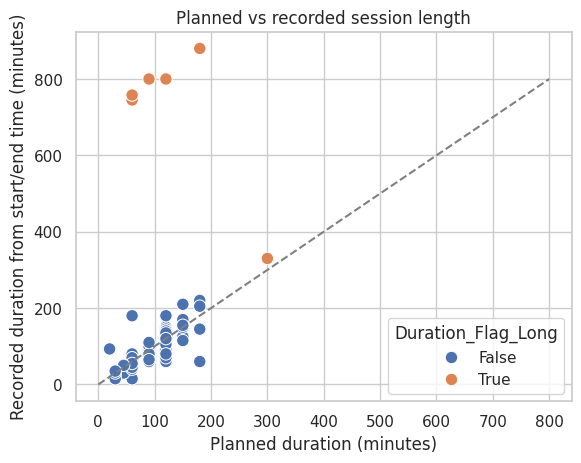

In [15]:
sns.scatterplot(data=df, x="Planned_Duration", y="Total_Duration_Minutes", hue="Duration_Flag_Long", s=80)
plt.plot([0, 800], [0, 800], linestyle="--", color="gray")   # line where planned = recorded
plt.title("Planned vs recorded session length")
plt.xlabel("Planned duration (minutes)")
plt.ylabel("Recorded duration from start/end time (minutes)")
plt.show()

Six sessions show 5–15 hour lengths, such as 21:00 → 09:25. These look like AM/PM entry errors rather than real sessions, so leave them out of any duration analysis.

In [16]:
# Look at the sessions flagged as very long
df[df["Duration_Flag_Long"]][["Start_Time", "End_Time", "Planned_Duration", "Total_Duration_Minutes"]]

,Start_Time,End_Time,Planned_Duration,Total_Duration_Minutes
4,21:00:00,09:25:00,60.0,745
12,16:20:00,04:58:00,60.0,758
14,12:30:00,18:00:00,300.0,330
40,20:00:00,09:20:00,120.0,800
55,13:30:00,02:50:00,90.0,800
64,19:00:00,09:40:00,180.0,880
